# Week 7 — AI Strategy and Innovation Management: from pilot to scale

In week 4 MegaTelCo's email-triage **pilot** worked: an LLM read 30 emails and the AI bill was tiny (about $0.20 per 1,000 emails).

Management is pleased and now asks two **scaling** questions:

1. **How do we run it at scale?** The options are: Buy a SaaS tool, keep calling an LLM API, or host our own open model? What does each really cost?
2. **What next?** The AI team has 12 more ideas and a budget of €1.5 million. Which ideas should get money, and how should we release it?

| Part | Topic |
|---|---|
| A | Pilot vs. production: what are we really paying for? |
| B | Total cost of ownership (TCO) of three options; break-even volume |
| C | Hidden costs and quality: from cheapest to best |
| D | One use case through the stage gates: expected value |
| E | The portfolio: headline picks vs. expected-value picks |

**No new maths lol.** Costs are added up, decisions use the expected-value idea from week 3 (simple probability calculations)

## Some more explanations:

- **Buy a SaaS tool**: We pay a company a monthly fee to use its ready-made software, which already has the AI inside. It's like renting a fully furnished flat: we move in quickly and the owner fixes everything, but we live by their rules and they can raise the rent.

- **Keep calling an LLM API**: We send each email over the internet to an AI model owned by a big company (Google, OpenAI and others) and pay a tiny amount for each one, as we did in week 4. It's like taking a taxi: we pay only for each trip and don't own a car, but we still have to plan the route ourselves (our prompts, our rules, connecting it to our systems).

- **Host our own open model**: We download a free AI model and run it on our own powerful computers (servers), so our data never leaves the company. It's like buying our own car: no fare per trip, but we pay for the car (GPUs), the fuel (Electicity bill), insurance and a driver (engineers and IT) even on days we barely use it. It only pays off if we drive a lot.

In [1]:
# The usual, non-fancy python libraries (Shows how simple these matters are)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Set the options once, and plot forever :)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (8, 4),
                     "axes.spines.top": False,
                     "axes.spines.right": False,
                     "axes.grid": True,
                     "grid.alpha": 0.3})

BLUE, ORANGE, GREEN, GREY, RED = "#2a78d6", "#eb6834", "#2e9e6a", "#7a7a7a", "#c4553d"
COLORS = {"SaaS": ORANGE, "API": BLUE, "Self-host": GREEN}

# Part A — Pilot vs. production

Remember the figure from Sculley et al. (2015): the **model is a small box** in the middle of a big system.
In the pilot we paid only for the small box (tokens). In production MegaTelCo also pays for everything around it:

| Cost line | Example for email triage |
|---|---|
| **Build (one-off)** | connect the AI to the CRM and the email system, write tests, security and GDPR review |
| **Fixed (per year)** | licences, monitoring tools, the people who keep it running |
| **Variable (per message)** | tokens (API), per-message fee (SaaS) |
| **Capacity (in steps)** | servers with GPUs if we host the model ourselves: one server handles a fixed number of messages |
| **Hidden (per year)** | maintenance, re-testing when the vendor changes the model, the cost of leaving a vendor |

MegaTelCo's volumes:

| Stage | Messages per month |
|---|---|
| Pilot (emails only) | 10,000 |
| All channels in Albania (email, chat, app, call transcripts) | 400,000 |
| The whole group (Albania + two neighbouring countries) | 3,000,000 |

# Part B — Total cost of ownership of three options

The IT team prices three ways to run email triage for **three years** (again these are illustrative numbers, but you can get real data from OneAlbania or Vodafone etc):

| Option | What it is |
|---|---|
| **SaaS** | a customer-service platform with AI triage built in. Little to build, but a fee for every message. |
| **API** | keep our own prompt (week 4) and pay an LLM provider per token. |
| **Self-host** | run an open-weight model on our own rented GPU servers. No per-message fee, but servers and staff. |

The build cost is spread over the three years. One full-time employee (FTE) costs MegaTelCo **€30,000 a year** (salary plus taxes, I know its BS :)).

In [3]:
# we compare the options over three years
YEARS = 3
# € per year for one full-time employee
FTE_COST = 30_000

OPTIONS = pd.DataFrame({
    #                         SaaS     API   Self-host
    "build_€":             [ 5_000, 25_000,  60_000],   # one-off: integration, tests, security review
    "fixed_€_per_year":    [ 6_000,  3_000,       0],   # platform licence / monitoring tools
    "staff_FTE":           [   0.1,    0.5,     1.5],   # people needed to run it (relative)
    "€_per_1000_msgs":     [   4.0,    3.0,     0.0],   # SaaS fee / API tokens
    "server_€_per_month":  [     0,      0,   2_000],   # one GPU server
    "server_capacity_M":   [np.nan, np.nan,     1.5],   # million messages per month one server handles
}, index=["SaaS", "API", "Self-host"])

OPTIONS.T

,SaaS,API,Self-host
build_€,5000.0,25000.0,60000.0
fixed_€_per_year,6000.0,3000.0,0.0
staff_FTE,0.1,0.5,1.5
€_per_1000_msgs,4.0,3.0,0.0
server_€_per_month,0.0,0.0,2000.0
server_capacity_M,NaN,NaN,1.5


In [4]:
# Function to calculate Total Cost Ownership (TCO)
def tco_per_year(opt, volume_m):
    """
    Calculates TCO for an option (opt) based on volume of messages it has to handle

    opt: SaaS, API, self-host
    volume_m: volume of messages in million
    
    Returns: Yearly cost (€) of one option at a volume of `volume_m` million messages per month
    """
    o = OPTIONS.loc[opt]
    build = o["build_€"] / YEARS
    fixed = o["fixed_€_per_year"]
    staff = o["staff_FTE"] * FTE_COST
    # 1 million = 1,000 x 1,000
    variable = o["€_per_1000_msgs"] * volume_m * 1_000 * 12
    if np.isnan(o["server_capacity_M"]):
        servers = 0
    else:
        # at least one server
        n_servers = np.ceil(np.maximum(volume_m, 1e-9) / o["server_capacity_M"])
        servers = n_servers * o["server_€_per_month"] * 12
    return pd.Series({"build": build, "fixed": fixed, "staff": staff,
                      "variable": variable, "servers": servers}).round(0)

In [8]:
# Example: the API option for all channels in Albania (0.4 million messages a month)
tco_per_year("API", 0.4)

build        8333.0
fixed        3000.0
staff       15000.0
variable    14400.0
servers         0.0
dtype: float64

In [9]:
tco_per_year("API", 0.4).sum()

np.float64(40733.0)

We can look at the cost for each option at three stages:

- **Pilot Stage**: 10k messages
- **Albania only**: 400k messages
- **Whole Grooup**: Balkans, 3M messages

In [10]:
VOLUMES = {"Pilot": 0.01, "Albania, all channels": 0.4, "Whole group": 3.0}

table = pd.DataFrame({stage: {opt: tco_per_year(opt, v).sum() for opt in OPTIONS.index}
                      for stage, v in VOLUMES.items()})
table.loc["cheapest"] = table.idxmin()
table

,Pilot,"Albania, all channels",Whole group
SaaS,11147.0,29867.0,154667.0
API,26693.0,40733.0,134333.0
Self-host,89000.0,89000.0,113000.0
cheapest,SaaS,SaaS,Self-host


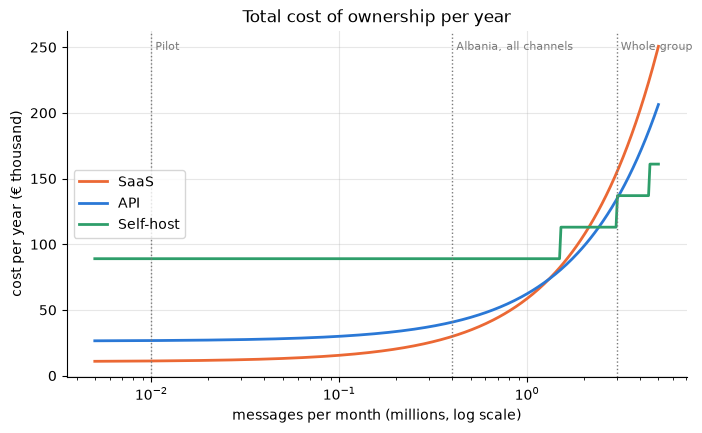

In [11]:
def plot_tco(cost_fn, title):
    v = np.geomspace(0.005, 5, 400)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for opt in OPTIONS.index:
        ax.plot(v, [cost_fn(opt, x) / 1000 for x in v], color=COLORS[opt], lw=2, label=opt)
    for stage, x in VOLUMES.items():
        ax.axvline(x, color=GREY, ls=":", lw=1)
        ax.text(x, ax.get_ylim()[1] * 0.97, " " + stage, fontsize=8, color=GREY, va="top")
    ax.set_xscale("log")
    ax.set_xlabel("messages per month (millions, log scale)")
    ax.set_ylabel("cost per year (€ thousand)")
    ax.set_title(title)
    ax.legend(loc="center left")
    plt.show()

plot_tco(lambda opt, v: tco_per_year(opt, v).sum(), "Total cost of ownership per year")

**Question**: Why Self-Host jumps and is not a smooth curve like the rest?

### Where does the cheapest option change?

`cheapest_at(volume)` returns the cheapest option. We scan volumes from small to large and print each point where the winner changes: the **break-even volumes**.

In [12]:
def cheapest_at(volume_m, cost_fn):
    costs = {opt: cost_fn(opt, volume_m) for opt in OPTIONS.index}
    return min(costs, key=costs.get)

def break_evens(cost_fn):
    grid = np.round(np.arange(0.01, 5.0, 0.01), 2)
    winner = cheapest_at(grid[0], cost_fn)
    print(f"from {grid[0]:.2f}M messages/month: {winner}")
    for v in grid[1:]:
        w = cheapest_at(v, cost_fn)
        if w != winner:
            print(f"from {v:.2f}M messages/month: {w}")
            winner = w

base_cost = lambda opt, v: tco_per_year(opt, v).sum()
break_evens(base_cost)

from 0.01M messages/month: SaaS
from 1.31M messages/month: API
from 2.41M messages/month: Self-host
from 3.01M messages/month: API
from 3.08M messages/month: Self-host


In [14]:
# Cheapest Option for the pilot (10k messages)
print(table.loc["cheapest"])
# Pilot: SaaS. Albania: SaaS. Whole group: Self-host

Pilot                         SaaS
Albania, all channels         SaaS
Whole group              Self-host
Name: cheapest, dtype: object


In [21]:
# At 0.4M messages a month, split the API's yearly cost into its parts (use tco_per_year). Which part is the largest? Is it the tokens?
print("API at 0.4M:\n", tco_per_year("API", 0.4).sort_values(ascending=False))
# We saw this when testing the tco_per_year() function: Its the staff

API at 0.4M:
 staff       15000.0
variable    14400.0
build        8333.0
fixed        3000.0
servers         0.0
dtype: float64


In [22]:
# The SaaS platform decided to raise the fee from €4 to €7 per 1,000 messages.What happens now?
# We can calculate it again

# First create a copy of options so you keep the original df intact (check pandas documentation on this)
saved = OPTIONS.copy()
# Now change the SaaS value from 4 to 7 euros per 1k messages
OPTIONS.loc["SaaS", "€_per_1000_msgs"] = 7.0
print("\nSaaS fee €7:")

# This will make all the calculations where the options break evenly (as defined above)
break_evens(base_cost)
print("-" * 40)

# Check only the cost for Albania at the new rate
print("Cost fot Albania")
print({opt: tco_per_year(opt, 0.4).sum() for opt in OPTIONS.index})

# restore the original numbers
OPTIONS = saved


SaaS fee €7:
from 0.01M messages/month: SaaS
from 0.33M messages/month: API
from 2.41M messages/month: Self-host
from 3.01M messages/month: API
from 3.08M messages/month: Self-host
----------------------------------------
Cost fot Albania
{'SaaS': np.float64(44267.0), 'API': np.float64(40733.0), 'Self-host': np.float64(89000.0)}


API is cheaper, about €40,700 vs. €44,300 a year that's the SaaS new price. The low build cost of SaaS was attractive at the beginning, but there is a catch with the vendors: once you depend fully on them, the vendor can raise the price and screw you up. The bottom-line: Negotiate the price for years 2-3 BEFORE you sign the contract.

Think of a scenario with AI APIs in a few years once companies depend fully on LLMs because they didnt give a damn about junior developers and paid only for Vibe coders who cant write a simple function without AI. Once they create the gap, they can increase the prices of API as they like, unless the Chinese companies screw them up. Otherwise its hard to imagine IPO of Anthropic to $1.2T

# Part C — Hidden costs and quality

**Hidden costs**. For AI, just like every other commodity, there are hidden costs. Every year someone has to fix the connections to our other systems, re-check everything when the AI company updates its model, and test a sample of results every month to make sure it still works. And if one day we want to leave a vendor, moving our data and processes away costs money too. These costs don't appear in the pilot, but they show up every year after launch.

**Quality**. A cheaper AI that makes more mistakes is not really cheaper. Each time the AI misses an angry customer who is about to leave, MegaTelCo loses that customer's future payments. Each time it raises a false alarm, a retention agent wastes time on a happy customer. In our numbers, the difference in mistakes between the options is worth far more than the difference in price. It's like hiring the cheapest accountant: you save on the fee and then lose much more on their errors, Just like they do in Albania, the main reason why this country is fairing so nicely in every direction. We have been through this when we talked about Confusion Matrix and Expected Values.

**The lesson: don't choose an AI option by its price tag. Choose it by its total cost over three years and by how much its mistakes cost you.**

## C1. Hidden technical debt

The IT team's first quote leaves out costs that appear only **after** launch (Sculley et al.: "changing anything changes everything", a paper worth reading): https://proceedings.neurips.cc/paper_files/paper/2015/file/86df7dcfd896fcaf2674f757a2463eba-Paper.pdf

| Hidden cost | SaaS | API | Self-host |
|---|---|---|---|
| **Maintenance** each year (fixing integrations, updating prompts and tests), as a share of the build cost | 20% | 20% | 30% |
| **Model changes**: the provider retires a model version; we re-test and re-tune (€ per year) | 0 (vendor does it) | 8,000 | 15,000 (we upgrade the model ourselves) |
| **Monitoring and evaluation**: a labelled sample every month, as in week 4 (€ per year) | 4,000 | 6,000 | 6,000 |
| **Exit cost**: moving data and processes away from the vendor one day (€, spread over 3 years) | 30,000 | 5,000 | 0 |

In [23]:
HIDDEN = pd.DataFrame({
    #                     SaaS     API   Self-host
    "maintenance_share": [0.20,   0.20,   0.30],
    "model_change_€":    [   0,  8_000, 15_000],
    "monitoring_€":      [4_000, 6_000,  6_000],
    "exit_€":            [30_000, 5_000,     0],
}, index=["SaaS", "API", "Self-host"])

HIDDEN.T

,SaaS,API,Self-host
maintenance_share,0.2,0.2,0.3
model_change_€,0.0,8000.0,15000.0
monitoring_€,4000.0,6000.0,6000.0
exit_€,30000.0,5000.0,0.0


Hidden costs per year: {'SaaS': 15000, 'API': 20667, 'Self-host': 39000}
from 0.01M messages/month: SaaS
from 1.78M messages/month: API
from 2.92M messages/month: Self-host
from 3.01M messages/month: API
from 3.59M messages/month: Self-host


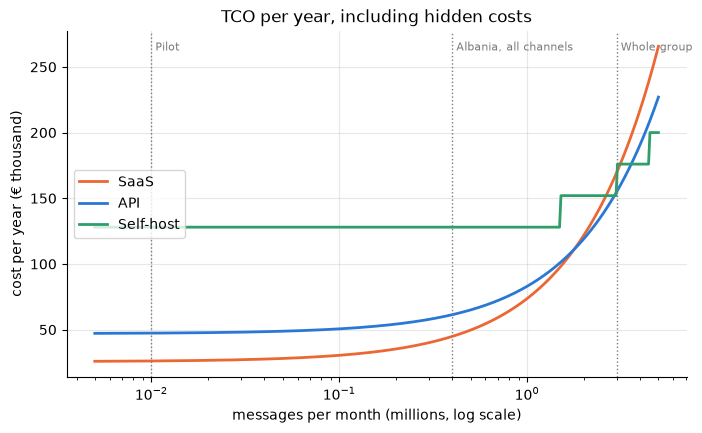

In [24]:
def hidden_per_year(opt):
    h = HIDDEN.loc[opt]
    return (h["maintenance_share"] * OPTIONS.loc[opt, "build_€"]
            + h["model_change_€"] + h["monitoring_€"] + h["exit_€"] / YEARS)

full_cost = lambda opt, v: tco_per_year(opt, v).sum() + hidden_per_year(opt)

print("Hidden costs per year:", {opt: round(hidden_per_year(opt)) for opt in OPTIONS.index})
break_evens(full_cost)
plot_tco(full_cost, "TCO per year, including hidden costs")

## C2. Quality: the errors cost more than the AI

The three options do not classify equally well. The IT team tested each on the same **labelled sample of 2,000 messages** (the week 4 method):

| | SaaS (generic model) | API (our week 4 prompt) | Self-host (smaller open model) |
|---|---|---|---|
| share of real high-risk messages caught | 78% | 85% | 82% |
| false alarms (calm messages sent to retention) | 2.0% | 1.0% | 1.5% |

And from week 4: each high-risk message caught is worth **+€57**, each false alarm costs **−€3**. At scale about **0.5%** of messages come from customers really at risk. We can put those numbers in program and see what happens. We have 400k messages from customers, and given the parameters above, we see the total profits, the costsand thenet profits of each option comapred to doing nothing

In [25]:
QUALITY = pd.DataFrame({
    "catch_rate":       [0.78, 0.85, 0.82],
    "false_alarm_rate": [0.020, 0.010, 0.015],
}, index=["SaaS", "API", "Self-host"])

AT_RISK_SHARE = 0.005

# € per message, from week 4: Keep a customer -> 57€, one FP -> 3€
GAIN_CAUGHT, COST_FALSE_ALARM = 57, -3

def value_per_year(opt, volume_m):
    msgs = volume_m * 1_000_000 * 12
    q = QUALITY.loc[opt]
    caught = msgs * AT_RISK_SHARE * q["catch_rate"]
    false_alarms = msgs * (1 - AT_RISK_SHARE) * q["false_alarm_rate"]
    return caught * GAIN_CAUGHT + false_alarms * COST_FALSE_ALARM

def net_table(volume_m):
    t = pd.DataFrame({"value €": {o: value_per_year(o, volume_m) for o in OPTIONS.index},
                      "full cost €": {o: full_cost(o, volume_m) for o in OPTIONS.index}})
    t["net value €"] = t["value €"] - t["full cost €"]
    return t.round(0).sort_values("net value €", ascending=False)

net_table(0.4)

,value €,full cost €,net value €
API,1019520.0,61400.0,958120.0
Self-host,906840.0,128000.0,778840.0
SaaS,780480.0,44867.0,735613.0


In [26]:
def breakdown(volume_m):
    # Step-by-step value and cost of each option at `volume_m` million messages a month
    # Messages per year
    msgs = volume_m * 1_000_000 * 12
    # messages from customers really at risk: 5%
    at_risk = msgs * AT_RISK_SHARE
    rows = {}
    for opt in OPTIONS.index:
        q = QUALITY.loc[opt]
        caught = at_risk * q["catch_rate"]
        false_alarms = (msgs - at_risk) * q["false_alarm_rate"]
        gain = caught * GAIN_CAUGHT
        loss = false_alarms * COST_FALSE_ALARM
        value = gain + loss
        cost = full_cost(opt, volume_m)
        rows[opt] = {
            "At-risk emails caught": f"{caught:,.0f} ({q['catch_rate']:.0%})",
            f"Gain from caught (× €{GAIN_CAUGHT})": f"€{gain:,.0f}",
            "False alarms": f"{false_alarms:,.0f} ({q['false_alarm_rate']:.1%})",
            f"Cost of false alarms (× €{-COST_FALSE_ALARM})": f"−€{-loss:,.0f}",
            "Value": f"€{value:,.0f}",
            "Full cost (TCO + hidden)": f"€{cost:,.0f}",
            "Net value": f"€{value - cost:,.0f}",
        }
    print(f"{msgs:,.0f} messages a year, {at_risk:,.0f} from customers at risk")
    return pd.DataFrame(rows)

breakdown(0.4)

4,800,000 messages a year, 24,000 from customers at risk


,SaaS,API,Self-host
At-risk emails caught,"18,720 (78%)","20,400 (85%)","19,680 (82%)"
Gain from caught (× €57),"€1,067,040","€1,162,800","€1,121,760"
False alarms,"95,520 (2.0%)","47,760 (1.0%)","71,640 (1.5%)"
Cost of false alarms (× €3),"−€286,560","−€143,280","−€214,920"
Value,"€780,480","€1,019,520","€906,840"
Full cost (TCO + hidden),"€44,867","€61,400","€128,000"
Net value,"€735,613","€958,120","€778,840"


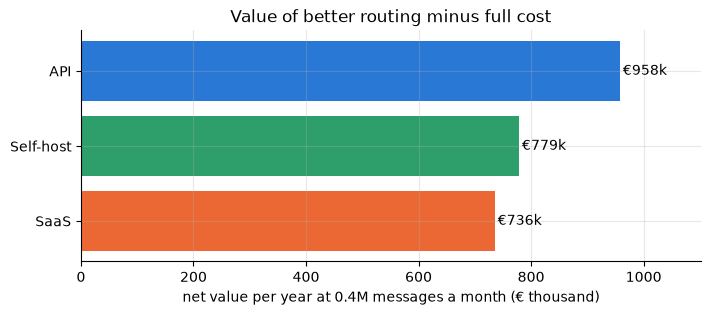

In [27]:
t = net_table(0.4)
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(t.index, t["net value €"] / 1000, color=[COLORS[o] for o in t.index])
for i, v in enumerate(t["net value €"]):
    ax.text(v / 1000 + 5, i, f"€{v/1000:,.0f}k", va="center")
ax.set_xlabel("net value per year at 0.4M messages a month (€ thousand)")
ax.set_xlim(0, t["net value €"].max() / 1000 * 1.15)
ax.invert_yaxis()
ax.set_title("Value of better routing minus full cost")
plt.show()

### With hidden costs, which option is cheapest for Albania (0.4M)?

In [33]:
print({opt: round(full_cost(opt, 0.4)) for opt in OPTIONS.index})

{'SaaS': 44867, 'API': 61400, 'Self-host': 128000}


### Which option has the highest NET value at 0.4M? Is it the cheapest one?

In [34]:
print(net_table(0.4))

             value €  full cost €  net value €
API        1019520.0      61400.0     958120.0
Self-host   906840.0     128000.0     778840.0
SaaS        780480.0      44867.0     735613.0


The API. Against SaaS it catches 7 points more of the 24,000 at-risk messages a year (about +€96,000) and sends half as many calm messages to retention (about +€143,000). Together about €239,000 a year, some 14 times the difference in cost. The cheapest option is NOT the best one.

### The SaaS vendor offers a 25% discount on its fee. Is that enough to make SaaS the best choice at 0.4M?

In [38]:
# The difference in value created by API vs SaaS
gap = net_table(0.4).loc["API", "net value €"] - net_table(0.4).loc["SaaS", "net value €"]
print(gap)

222507.0


In [39]:
saas_fee = OPTIONS.loc["SaaS", "€_per_1000_msgs"] * 0.4 * 1000 * 12
print(saas_fee)

19200.0


In [41]:
discounted_fee = 0.25 * saas_fee
print(discounted_fee)

4800.0


In [47]:
print(f"Even at 25% discount, SaaS would only cover {(discounted_fee / gap) * 100:.2f}% of net gap created by the API")

Even at 25% discount, SaaS would only cover 2.16% of net gap created by the API


### **IMPORTANT**: Compare vendors on what their errors cost us on OUR labelled data first, and on price second: at our volume a few points of accuracy are worth far more than the whole AI bill."

---
# This part of the notebook is totally optional

# Part D — One use case through the stage gates.

From the lecture: an AI idea passes through **gates**. At each gate we can stop and save the money for the next stage.

### Gates don't make a project more likely to succeed. They make failure cheaper.

```
idea ─► PoC ── gate ──► pilot ── gate ──► scale ──► value for 3 years
        €20k   p=0.7   €80k    p=0.5   €250k  p=0.6
```

Example: **churn uplift targeting**. A PoC costs €20k and works with probability 0.7. A pilot costs €80k and passes with probability 0.5. Scaling costs €250k and succeeds (people actually use it, the value appears) with probability 0.6. If it succeeds it is worth **€900k a year**.

### Some Terminology:

- **c** stands for cost, so €20k is 20 in the formula
- **p** is probability

### The Formulas:

**Expected value with gates** (we only pay for a stage if the previous one passed):

`EV = −c_PoC + p_PoC × ( −c_pilot + p_pilot × ( −c_scale + p_scale × value × 3 ) )`

**Without gates** (the board approves the whole budget at once and nobody stops it):

`EV = −(c_PoC + c_pilot + c_scale) + p_PoC × p_pilot × p_scale × value × 3`

In [50]:
def ev_with_gates(r, years=YEARS):
    return -r["c_poc"] + r["p_poc"] * (-r["c_pilot"] + r["p_pilot"] * (-r["c_scale"] + r["p_scale"] * r["value"] * years))

def ev_without_gates(r, years=YEARS):
    return -(r["c_poc"] + r["c_pilot"] + r["c_scale"]) + r["p_poc"] * r["p_pilot"] * r["p_scale"] * r["value"] * years

# Define the probabilities and values
churn = pd.Series({"value": 900, "p_poc": 0.7, "p_pilot": 0.5, "p_scale": 0.6,
                   "c_poc": 20, "c_pilot": 80, "c_scale": 250})
# Numbers are all in k
churn

value      900.0
p_poc        0.7
p_pilot      0.5
p_scale      0.6
c_poc       20.0
c_pilot     80.0
c_scale    250.0
dtype: float64

In [49]:
print(f"P(reaching value) = {churn.p_poc * churn.p_pilot * churn.p_scale:.0%}")
print(f"EV with gates:    €{ev_with_gates(churn):,.0f}k")
print(f"EV without gates: €{ev_without_gates(churn):,.0f}k")

P(reaching value) = 21%
EV with gates:    €404k
EV without gates: €217k


### The way one of these calculations works (Stick the variables in the formula):

**Scale stage**:  -250 + 0.6 x 900 x 3 = -250 + 1,620 = 1,370

**Pilot stage**:  -80  + 0.5 x 1,370 = -80  + 685 = 605

**PoC stage**:  -20  + 0.7 x 605 = -20 + 423.5 = 403.5 -> about €404k

### Some Important Concepts:

- Chance of reaching €2.7m for 3 years is the same for both, gated and non-gated
- Expected payoff is also the same: 0.21 × 2,700 = €567k
- Expected cost	€350k Changes:
  - For non-gated, its all spent €350k
  - For gated, only 20 + 0.7 × 80 + 0.35 × 250 = €164k is spent
- Thus, expected values for both
  - 567 - 350 = €217k
  - 567 - 164 = €404k

The whole €187k difference comes from money not spent on projects that had already failed.

## Pilot purgatory 

The pilot works, but no manager owns the scale-up, so p_scale falls from 0.6 to 0.3. Recompute both EVs. What would you change in the organisation, not in the model?

In [52]:
purgatory = churn.copy(); purgatory["p_scale"] = 0.3
print(f"with gates €{ev_with_gates(purgatory):,.0f}k, without gates €{ev_without_gates(purgatory):,.0f}k")

with gates €120k, without gates €-66k


### Possible Solution

With gates the EV falls from about €404k to about €120k, and without gates it is now NEGATIVE. The model is the same, and what changed is whether someone owns the scale-up. Fix it before the pilot starts: name a business owner, agree what "success" means (a kill criterion), and reserve the scale-up budget (Visionary Leadership)

# Part E — The portfolio

The AI team has **12 ideas**. For each, the team estimated the value at scale (€k per year), the probability of passing each gate, and the cost of each stage.
The budget is **€1.5 million**. To be safe, the finance team reserves each chosen project's **full** cost (PoC + pilot + scale) when it is approved.

In [53]:
IDEAS = pd.DataFrame([
    # use case,                      value, p_poc, p_pilot, p_scale, c_poc, c_pilot, c_scale   (€k)
    ("Email triage (week 4)",          250, 0.90, 0.80, 0.75, 10,  40, 120),
    ("Churn uplift targeting",         900, 0.70, 0.50, 0.60, 20,  80, 250),
    ("Network fault prediction",      1500, 0.50, 0.40, 0.50, 40, 150, 600),
    ("Billing chatbot",                600, 0.85, 0.55, 0.50, 15,  60, 200),
    ("Invoice / document AI",          180, 0.90, 0.85, 0.80, 10,  30,  80),
    ("Dynamic pricing of bundles",    2000, 0.40, 0.35, 0.40, 50, 200, 800),
    ("Shop staff scheduling",          150, 0.80, 0.75, 0.70, 10,  30,  70),
    ("SIM-swap fraud detection",       700, 0.70, 0.65, 0.70, 25,  90, 250),
    ("GenAI sales assistant",         1200, 0.60, 0.40, 0.35, 30, 120, 500),
    ("CV screening for HR",            120, 0.80, 0.60, 0.40, 10,  40,  90),
    ("Agentic technical support",     1800, 0.45, 0.30, 0.30, 40, 180, 700),
    ("Contract search (RAG) for legal",200, 0.85, 0.70, 0.65, 10,  35,  90),
], columns=["use_case", "value", "p_poc", "p_pilot", "p_scale", "c_poc", "c_pilot", "c_scale"]).set_index("use_case")

IDEAS["P(success)"] = IDEAS["p_poc"] * IDEAS["p_pilot"] * IDEAS["p_scale"]
IDEAS["full cost"] = IDEAS["c_poc"] + IDEAS["c_pilot"] + IDEAS["c_scale"]

IDEAS["EV gates"] = IDEAS.apply(ev_with_gates, axis=1)
IDEAS["EV per € reserved"] = IDEAS["EV gates"] / IDEAS["full cost"]

IDEAS[["value", "P(success)", "full cost", "EV gates", "EV per € reserved"]].round(2).sort_values("EV per € reserved", ascending=False)

,value,P(success),full cost,EV gates,EV per € reserved
use_case,,,,,
Invoice / document AI,180,0.61,120,232.28,1.94
Email triage (week 4),250,0.54,170,272.60,1.60
SIM-swap fraud detection,700,0.32,365,467.10,1.28
Churn uplift targeting,900,0.21,350,403.50,1.15
Shop staff scheduling,150,0.42,110,113.00,1.03
Contract search (RAG) for legal,200,0.39,135,138.75,1.03
Billing chatbot,600,0.23,275,261.25,0.95
Network fault prediction,1500,0.10,790,215.00,0.27
GenAI sales assistant,1200,0.08,650,80.40,0.12


## E1. Two ways to choose

- **Headline picks** (what often happens in a board meeting): fund the ideas with the **biggest value at scale** first, until the budget runs out.
- **EV picks**: fund the ideas with the highest **expected value per euro reserved** first (never an idea with negative EV).

In [54]:
# €1.5 M
BUDGET = 1_500

def choose(order):
    chosen, spent = [], 0
    for idea in order:
        if spent + IDEAS.loc[idea, "full cost"] <= BUDGET:
            chosen.append(idea)
            spent += IDEAS.loc[idea, "full cost"]
    return chosen

headline_picks = choose(IDEAS.sort_values("value", ascending=False).index)
ev_picks = choose(IDEAS[IDEAS["EV gates"] > 0].sort_values("EV per € reserved", ascending=False).index)

In [55]:
headline_picks

['Dynamic pricing of bundles', 'Churn uplift targeting']

In [56]:
ev_picks

['Invoice / document AI',
 'Email triage (week 4)',
 'SIM-swap fraud detection',
 'Churn uplift targeting',
 'Contract search (RAG) for legal',
 'Shop staff scheduling']

## E2. Simulate 10,000 possible futures

For each future, each chosen idea passes or fails each gate at random (with its probabilities).
We compare four policies: headline or EV picks, **with** gates (stop after a failure) or **without** gates (all the money is spent anyway).

In [57]:
rng = np.random.default_rng(7)
N = 10_000

def simulate(chosen, gates, ideas=IDEAS, n=N):
    # Portfolio result (€k over 3 years) in each of n simulated futures
    result = np.zeros(n)
    for idea in chosen:
        r = ideas.loc[idea]
        passed_poc = rng.random(n) < r["p_poc"]
        passed_pilot = passed_poc & (rng.random(n) < r["p_pilot"])
        succeeded = passed_pilot & (rng.random(n) < r["p_scale"])
        if gates:
            cost = r["c_poc"] + passed_poc * r["c_pilot"] + passed_pilot * r["c_scale"]
        else:
            cost = r["full cost"]
        result += succeeded * r["value"] * YEARS - cost
    return result

POLICIES = {"Headline, no gates": (headline_picks, False), "Headline, gates": (headline_picks, True),
            "EV, no gates": (ev_picks, False), "EV, gates": (ev_picks, True)}
sims = {name: simulate(ch, g) for name, (ch, g) in POLICIES.items()}

summary = pd.DataFrame({name: {"average €k": s.mean(),
                               "bad year (10th percentile) €k": np.percentile(s, 10),
                               "P(losing money)": (s < 0).mean()} for name, s in sims.items()}).T
summary.round(2)

,average €k,bad year (10th percentile) €k,P(losing money)
"Headline, no gates",-486.80,-1400.0,0.74
"Headline, gates",502.40,-600.0,0.75
"EV, no gates",1134.60,-710.0,0.29
"EV, gates",1616.69,10.0,0.10


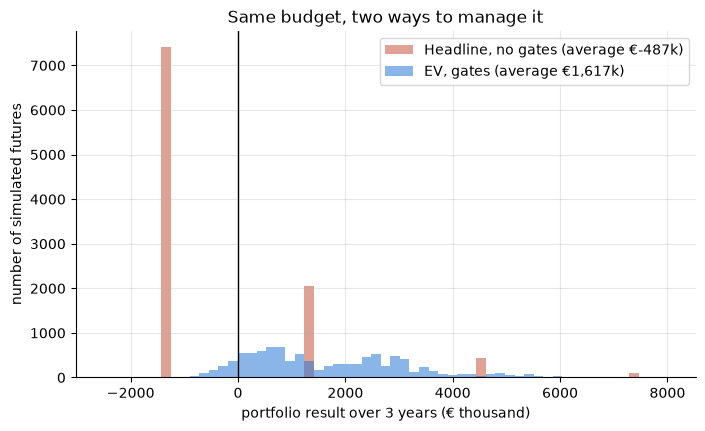

In [58]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(-2500, 8000, 60)
for name, color in [("Headline, no gates", RED), ("EV, gates", BLUE)]:
    ax.hist(sims[name], bins=bins, alpha=0.55, color=color, label=f"{name} (average €{sims[name].mean():,.0f}k)")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("portfolio result over 3 years (€ thousand)")
ax.set_ylabel("number of simulated futures")
ax.set_title("Same budget, two ways to manage it")
ax.legend()
plt.show()

In [ ]:
# Exercise 5
# 1. Rank the four policies by average result. How much of the improvement comes from WHICH ideas
#    we pick, and how much from HOW we release the money (gates)?
# 2. The headline picks have the biggest values at scale. Why do they do so badly?
#    (Look at their P(success).)
# 3. Look at "P(losing money)" for EV with gates. Even the best policy loses money in some futures.
#    How would you explain that to the board?
# 4. Pilot purgatory for the whole company: lower every p_scale by 0.2 (make a copy of IDEAS) and
#    re-run the simulation for "EV, gates". How much is a clear business owner for each project
#    worth to the portfolio?

In [28]:
# Rank the four policies by average result. How much of the improvement comes from WHICH ideas we pick, and how much from HOW we release the money (gates)?
print(summary["average €k"].sort_values(ascending=False).round(0))

EV, gates             1617.0
EV, no gates          1135.0
Headline, gates        502.0
Headline, no gates    -487.0
Name: average €k, dtype: float64


In [30]:
pick_effect = sims["EV, no gates"].mean() - sims["Headline, no gates"].mean()
gate_effect = sims["EV, gates"].mean() - sims["EV, no gates"].mean()
print(f"Picking by EV adds about €{pick_effect:,.0f}k; adding gates adds about €{gate_effect:,.0f}k more.")

Picking by EV adds about €1,621k; adding gates adds about €482k more.


Order: EV with gates > EV without gates > headline with gates > headline without gates. Choosing better ideas matters most, gates add a large amount on top.

In [31]:
# The headline picks have the biggest values at scale. Why do they do so badly?
print(IDEAS.loc[headline_picks, ["value", "P(success)", "full cost"]])

                            value  P(success)  full cost
use_case                                                
Dynamic pricing of bundles   2000       0.056       1050
Churn uplift targeting        900       0.210        350


Dynamic pricing and churn uplift use the whole budget. Dynamic pricing reaches its value only about 6% of the time and costs €1.05 million. A big headline value with a small chance of success and a large cost is a lottery ticket, not a strategy. It resembles Albanian Policies for recycling, digitalization and high-tech part: Cool from outside, but empty inside -> bound to fail

Look at "P(losing money)" for EV with gates. Even the best policy loses money in some futures. How would you explain that to the board?

Some ideas will fail: that is innovation. The board should judge the PORTFOLIO, not each project. With gates, the losses in bad futures are small (failed ideas are stopped early), and the winners pay for them.

This is another huge difference between developed and developing countries: Fail but look at the long-term effects.

In [34]:
# Pilot purgatory for the whole company: lower every p_scale by 0.2 (make a copy of IDEAS) and 
# re-run the simulation for "EV, gates". How much is a clear business owner for each project
# worth to the portfolio?
purg = IDEAS.copy()
purg["p_scale"] = (purg["p_scale"] - 0.2).clip(lower=0)
s_purg = simulate(ev_picks, True, ideas=purg)
print(f"EV, gates: €{sims['EV, gates'].mean():,.0f}k  ->  with purgatory €{s_purg.mean():,.0f}k "
      f"(P(losing money) {(s_purg < 0).mean():.0%})")

EV, gates: €1,617k  ->  with purgatory €921k (P(losing money) 27%)


The average result falls by several hundred thousand euros over three years and the chance of losing money rises sharply. That is the value of organisation: owners, budgets for scale-up, and changed processes, not better models.

### Optional (fast groups): gates free up budget

With gates, most reserved money is never spent. Suppose finance reserves only the **expected** cost
`c_poc + p_poc × (c_pilot + p_pilot × c_scale)` for each project. How many ideas can MegaTelCo start now, and what is the simulated average result?

In [36]:
IDEAS["expected cost"] = IDEAS["c_poc"] + IDEAS["p_poc"] * (IDEAS["c_pilot"] + IDEAS["p_pilot"] * IDEAS["c_scale"])
order = (IDEAS["EV gates"] / IDEAS["expected cost"]).sort_values(ascending=False).index
chosen, spent = [], 0

for idea in order:
    if IDEAS.loc[idea, "EV gates"] > 0 and spent + IDEAS.loc[idea, "expected cost"] <= BUDGET:
        chosen.append(idea); spent += IDEAS.loc[idea, "expected cost"]
        
s_more = simulate(chosen, True)

print(f"{len(chosen)} ideas (instead of {len(ev_picks)}): {chosen}")
print("-" * 60)
print(f"average €{s_more.mean():,.0f}k, P(losing money) {(s_more < 0).mean():.0%}")

9 ideas (instead of 6): ['Churn uplift targeting', 'Invoice / document AI', 'SIM-swap fraud detection', 'Email triage (week 4)', 'Billing chatbot', 'Contract search (RAG) for legal', 'Shop staff scheduling', 'Network fault prediction', 'Dynamic pricing of bundles']
------------------------------------------------------------
average €2,184k, P(losing money) 17%


# Part F — Your project (feeds your one-page problem framing)

Fill in the table for your team's use case. Rough numbers are fine; say where each comes from.

| | Your estimate | Source / assumption |
|---|---|---|
| Value per year if it works at scale (€) | | |
| Build cost, one-off (€) | | |
| Fixed cost per year (people, licences) (€) | | |
| Variable cost per unit (message, document, customer) (€) | | |
| Best option: SaaS, API or self-host? Why? | | |
| P(PoC works) · P(pilot passes) · P(it scales) | | |
| **Kill criterion** at the PoC gate (a number you will measure) | | |
| **Kill criterion** at the pilot gate | | |
| Who owns the scale-up (a role in the company)? | | |

*Your table here.*

---
## Discussion (5 minutes)
- A vendor says: *"Our platform is 40% cheaper than building it yourself."* Using today's results, what would you ask before signing?
- Iansiti and Lakhani say AI-first firms are built around an "AI factory". Which part of the factory (data pipeline, algorithms, experimentation platform, infrastructure) was missing in the "pilot purgatory" scenario?
- Your project: what is the one number that would make you stop it?

---
# Exit ticket (on paper)

**Q1.** An API costs €3 per 1,000 messages and €20,000 a year in staff. A self-hosted model costs €50,000 a year in total (servers and staff), whatever the volume. Above what monthly volume is self-hosting cheaper?

**Q2.** A PoC costs €10k and works with probability 0.5. If it works, a €40k project follows, worth €200k for sure. What is the EV with a gate after the PoC? And without the gate?

**Q3.** Give two reasons why an AI pilot that "worked" may never reach production.